In [14]:
!pip install -q -U yfinance

In [15]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm


[*********************100%***********************]  1 of 1 completed


Days: 4598
Typical daily move: 1.28 %


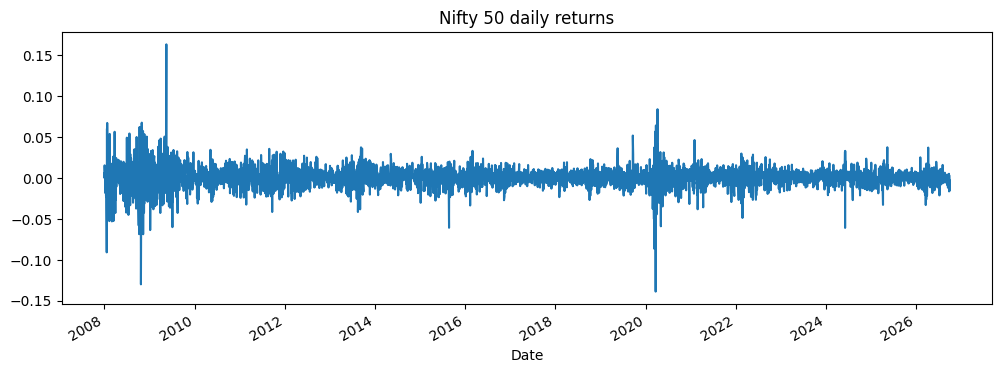

In [16]:
nifty = yf.download("^NSEI", start="2008-01-01", end="2026-10-01",
                    auto_adjust=True)["Close"].squeeze().dropna()
ret = np.log(nifty).diff().dropna()
loss = -ret     # we care about falls, so flip the sign: a positive loss = the market fell

print("Days:", len(ret))
print("Typical daily move:", round(ret.std() * 100, 2), "%")

ret.plot(figsize=(12, 4), title="Nifty 50 daily returns")
plt.show()

In [17]:
sd = ret.std()
for k in [3, 4, 5]:
    actual = (loss > k * sd).sum()
    expected = len(loss) * norm.sf(k)
    print(f"Falls bigger than {k}x typical move: actual = {actual}, normal model expects = {expected:.2f}")

Falls bigger than 3x typical move: actual = 38, normal model expects = 6.21
Falls bigger than 4x typical move: actual = 22, normal model expects = 0.15
Falls bigger than 5x typical move: actual = 7, normal model expects = 0.00


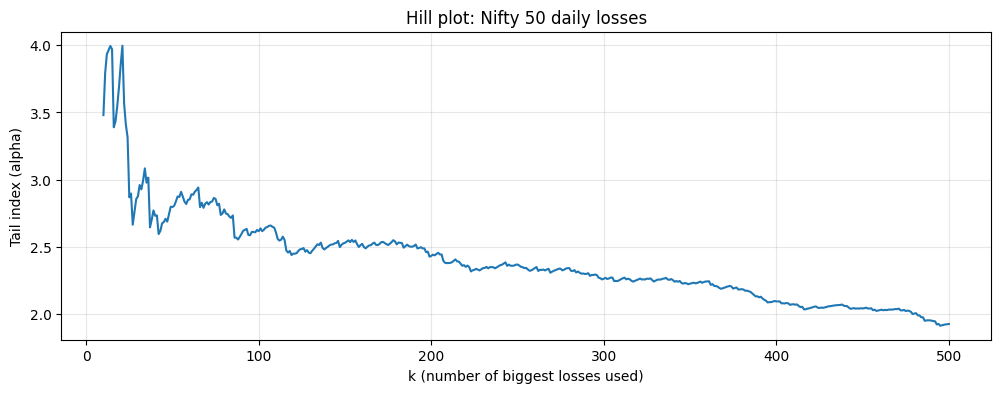

In [18]:
x = np.sort(loss.values)[::-1]     # all losses, biggest first
n = len(x)

ks = np.arange(10, 501)
alphas = [1 / np.mean(np.log(x[:k] / x[k])) for k in ks]

plt.figure(figsize=(12, 4))
plt.plot(ks, alphas)
plt.xlabel("k (number of biggest losses used)")
plt.ylabel("Tail index (alpha)")
plt.title("Hill plot: Nifty 50 daily losses")
plt.grid(alpha=0.3)
plt.show()

In [19]:
k = 150
alpha = 1 / np.mean(np.log(x[:k] / x[k]))
print("Tail index alpha (k = 150):", round(alpha, 2))

rows = []
for p in [0.99, 0.995, 0.999]:
    normal_var = loss.mean() + norm.ppf(p) * loss.std()
    hill_var = x[k] * (k / (n * (1 - p))) ** (1 / alpha)
    actual = np.quantile(loss, p)
    rows.append((f"{p*100:.1f}%", round(normal_var * 100, 2),
                 round(hill_var * 100, 2), round(actual * 100, 2)))

print(pd.DataFrame(rows, columns=["Confidence", "Normal VaR %",
                                  "Hill VaR %", "What actually happened %"]))

Tail index alpha (k = 150): 2.53
  Confidence  Normal VaR %  Hill VaR %  What actually happened %
0      99.0%          2.95        3.59                      3.58
1      99.5%          3.27        4.72                      4.90
2      99.9%          3.93        8.92                      7.30


Days tested: 3598 | Expected breaches at 99%: 36.0
Normal: breaches = 50, test p-value = 0.027
Hill: breaches = 37, test p-value = 0.865


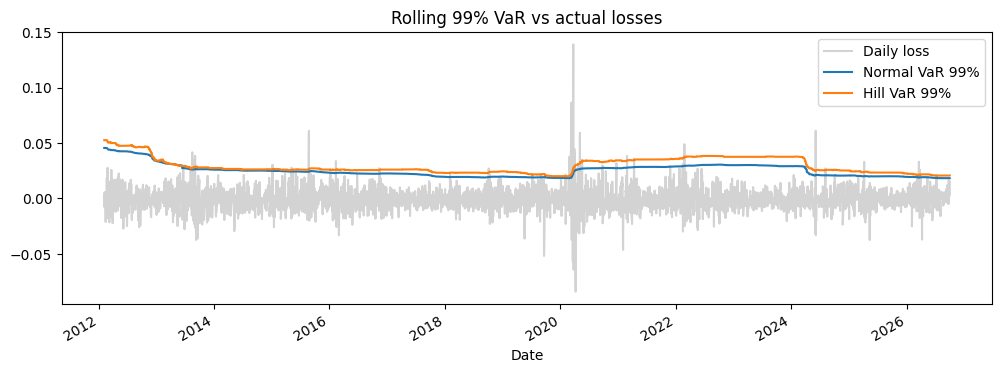

In [20]:
from scipy.stats import chi2

window = 1000
k_bt = 50
p = 0.99
lv = loss.values
normal_list, hill_list = [], []

for t in range(window, len(lv)):
    past = lv[t - window : t]
    normal_list.append(past.mean() + norm.ppf(p) * past.std())
    xs = np.sort(past)[::-1]
    a = 1 / np.mean(np.log(xs[:k_bt] / xs[k_bt]))
    hill_list.append(xs[k_bt] * (k_bt / (window * (1 - p))) ** (1 / a))

bt = pd.DataFrame({"loss": lv[window:], "Normal": normal_list, "Hill": hill_list},
                  index=loss.index[window:])

def kupiec(x, T, p):
    q = 1 - p
    phat = x / T
    lr = -2 * ((T - x) * np.log(1 - q) + x * np.log(q)
               - (T - x) * np.log(1 - phat) - x * np.log(phat))
    return chi2.sf(lr, 1)

T = len(bt)
print("Days tested:", T, "| Expected breaches at 99%:", round(T * (1 - p), 1))
for m in ["Normal", "Hill"]:
    b = (bt["loss"] > bt[m]).sum()
    print(f"{m}: breaches = {b}, test p-value = {kupiec(b, T, p):.3f}")

ax = bt["loss"].plot(figsize=(12, 4), color="lightgray", label="Daily loss")
bt["Normal"].plot(ax=ax, label="Normal VaR 99%")
bt["Hill"].plot(ax=ax, label="Hill VaR 99%")
plt.title("Rolling 99% VaR vs actual losses")
plt.legend()
plt.show()

In [21]:
bt["Normal breach"] = bt["loss"] > bt["Normal"]
bt["Hill breach"] = bt["loss"] > bt["Hill"]

by_year = bt[["Normal breach", "Hill breach"]].groupby(bt.index.year).sum()
by_year["Expected"] = (bt.groupby(bt.index.year).size() * 0.01).round(1)
print(by_year)

      Normal breach  Hill breach  Expected
Date                                      
2012              0            0       2.2
2013              4            3       2.5
2014              0            0       2.4
2015              3            3       2.4
2016              3            2       2.4
2017              0            0       2.5
2018              4            3       2.4
2019              2            1       2.4
2020             19           15       2.5
2021              3            2       2.5
2022              2            1       2.5
2023              0            0       2.4
2024              3            2       2.5
2025              1            1       2.5
2026              6            4       1.8


         Model  Breaches  Kupiec p  2020  Worst year  Years with 0  Avg VaR %
0       Normal        50     0.027    19          19             4       2.52
1         Hill        37     0.865    15          15             4       2.94
2  EWMA Normal        69     0.000    13          13             0       2.14
3    EWMA Hill        45     0.146    10          10             2       2.52


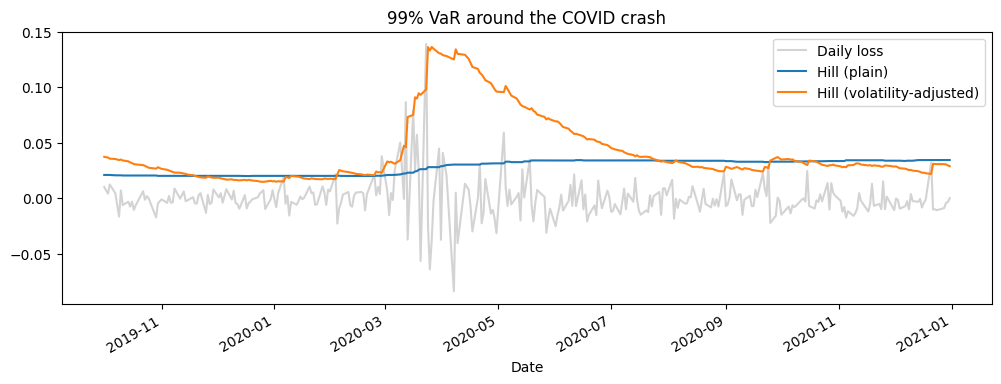

In [22]:
# 1. EWMA volatility (uses only past days)
lam = 0.94
r = ret.values
var_ewma = np.zeros(len(r))
var_ewma[0] = np.var(r[:20])
for t in range(1, len(r)):
    var_ewma[t] = lam * var_ewma[t - 1] + (1 - lam) * r[t - 1] ** 2
vol = np.sqrt(var_ewma)

# 2. adjusted losses
zl = lv / vol

# 3 & 4. rolling VaR
ewma_normal, ewma_hill = [], []
for t in range(window, len(lv)):
    ewma_normal.append(vol[t] * norm.ppf(p))
    zs = np.sort(zl[t - window : t])[::-1]
    a = 1 / np.mean(np.log(zs[:k_bt] / zs[k_bt]))
    q = zs[k_bt] * (k_bt / (window * (1 - p))) ** (1 / a)
    ewma_hill.append(vol[t] * q)

bt["EWMA Normal"] = ewma_normal
bt["EWMA Hill"] = ewma_hill

# compare all 4
rows = []
for m in ["Normal", "Hill", "EWMA Normal", "EWMA Hill"]:
    br = bt["loss"] > bt[m]
    yearly = br.groupby(bt.index.year).sum()
    rows.append((m, br.sum(), round(kupiec(br.sum(), T, p), 3),
                 yearly.get(2020, 0), yearly.max(), (yearly == 0).sum(),
                 round(bt[m].mean() * 100, 2)))
print(pd.DataFrame(rows, columns=["Model", "Breaches", "Kupiec p", "2020",
                                  "Worst year", "Years with 0", "Avg VaR %"]))

# zoom in on COVID
z20 = bt.loc["2019-10-01":"2020-12-31"]
ax = z20["loss"].plot(figsize=(12, 4), color="lightgray", label="Daily loss")
z20["Hill"].plot(ax=ax, label="Hill (plain)")
z20["EWMA Hill"].plot(ax=ax, label="Hill (volatility-adjusted)")
plt.title("99% VaR around the COVID crash")
plt.legend()
plt.show()

In [23]:
def run_models(p=0.99, k_bt=50, lam=0.94):
    v = np.zeros(len(r))
    v[0] = np.var(r[:20])
    for t in range(1, len(r)):
        v[t] = lam * v[t - 1] + (1 - lam) * r[t - 1] ** 2
    vol = np.sqrt(v)
    zl = lv / vol

    out = {"Normal": [], "Hill": [], "EWMA Normal": [], "EWMA Hill": []}
    for t in range(window, len(lv)):
        past = lv[t - window : t]
        out["Normal"].append(past.mean() + norm.ppf(p) * past.std())
        xs = np.sort(past)[::-1]
        a = 1 / np.mean(np.log(xs[:k_bt] / xs[k_bt]))
        out["Hill"].append(xs[k_bt] * (k_bt / (window * (1 - p))) ** (1 / a))
        out["EWMA Normal"].append(vol[t] * norm.ppf(p))
        zs = np.sort(zl[t - window : t])[::-1]
        a2 = 1 / np.mean(np.log(zs[:k_bt] / zs[k_bt]))
        out["EWMA Hill"].append(vol[t] * zs[k_bt] * (k_bt / (window * (1 - p))) ** (1 / a2))

    actual = lv[window:]
    res = {}
    for m, vals in out.items():
        b = int((actual > np.array(vals)).sum())
        res[m] = f"{b} ({kupiec(b, T, p):.2f})"
    return res

settings = [
    ("Main: 99%, k=50, lambda=0.94", dict()),
    ("99.5% confidence", dict(p=0.995)),
    ("k = 30", dict(k_bt=30)),
    ("k = 80", dict(k_bt=80)),
    ("lambda = 0.97", dict(lam=0.97)),
]
rows = []
for name, s in settings:
    exp = round(T * (1 - s.get("p", 0.99)), 1)
    rows.append({"Setting": name, "Expected": exp, **run_models(**s)})

pd.set_option("display.width", 200)
print(pd.DataFrame(rows))

                        Setting  Expected     Normal       Hill EWMA Normal  EWMA Hill
0  Main: 99%, k=50, lambda=0.94      36.0  50 (0.03)  37 (0.86)   69 (0.00)  45 (0.15)
1              99.5% confidence      18.0  41 (0.00)  18 (1.00)   53 (0.00)  17 (0.81)
2                        k = 30      36.0  50 (0.03)  38 (0.74)   69 (0.00)  50 (0.03)
3                        k = 80      36.0  50 (0.03)  31 (0.39)   69 (0.00)  39 (0.62)
4                 lambda = 0.97      36.0  50 (0.03)  37 (0.86)   65 (0.00)  40 (0.51)


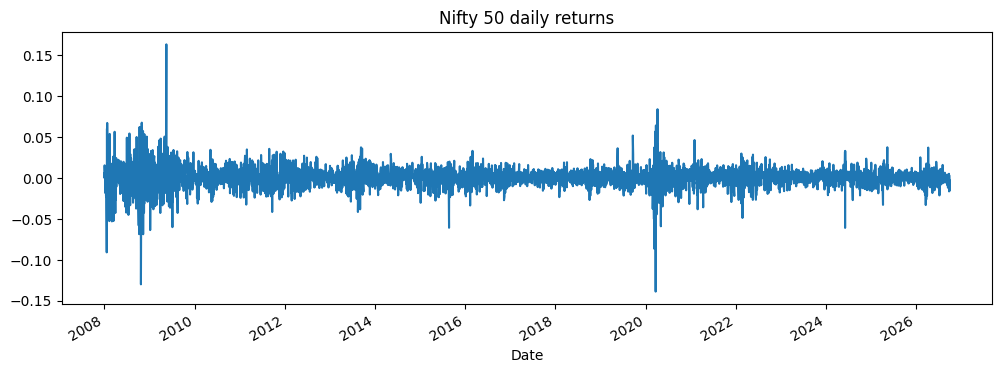

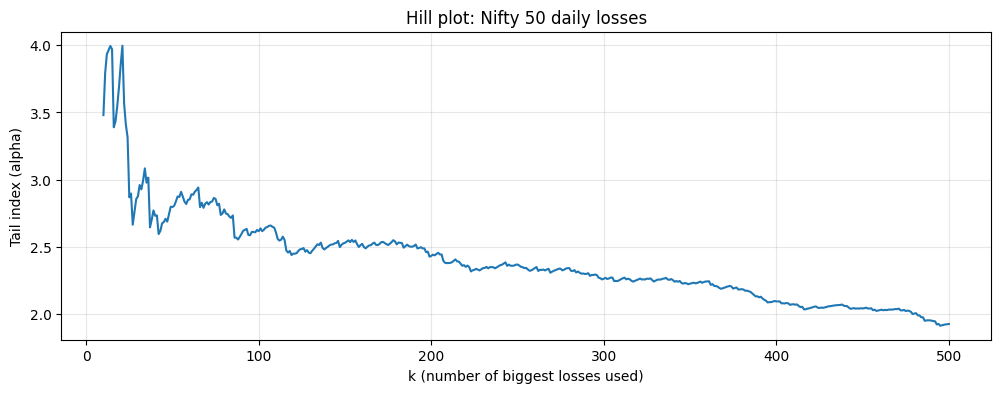

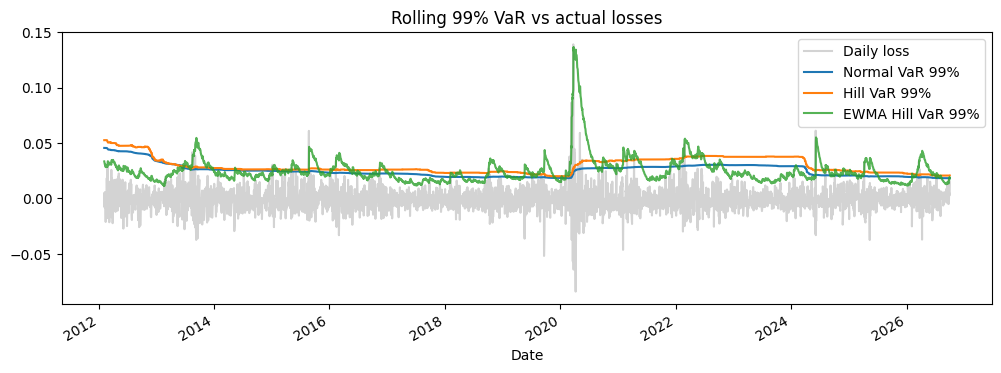

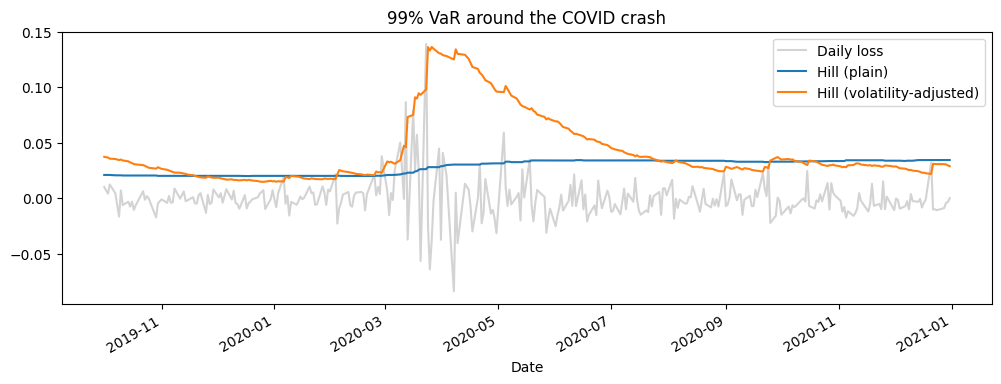

In [24]:
# 1. daily returns
ret.plot(figsize=(12, 4), title="Nifty 50 daily returns")
plt.savefig("/content/returns.png", dpi=150, bbox_inches="tight"); plt.show()

# 2. Hill plot
plt.figure(figsize=(12, 4))
plt.plot(ks, alphas)
plt.xlabel("k (number of biggest losses used)"); plt.ylabel("Tail index (alpha)")
plt.title("Hill plot: Nifty 50 daily losses"); plt.grid(alpha=0.3)
plt.savefig("/content/hill_plot.png", dpi=150, bbox_inches="tight"); plt.show()

# 3. rolling VaR vs losses
ax = bt["loss"].plot(figsize=(12, 4), color="lightgray", label="Daily loss")
bt["Normal"].plot(ax=ax, label="Normal VaR 99%")
bt["Hill"].plot(ax=ax, label="Hill VaR 99%")
bt["EWMA Hill"].plot(ax=ax, label="EWMA Hill VaR 99%", alpha=0.8)
plt.title("Rolling 99% VaR vs actual losses"); plt.legend()
plt.savefig("/content/var_backtest.png", dpi=150, bbox_inches="tight"); plt.show()

# 4. COVID zoom
ax = z20["loss"].plot(figsize=(12, 4), color="lightgray", label="Daily loss")
z20["Hill"].plot(ax=ax, label="Hill (plain)")
z20["EWMA Hill"].plot(ax=ax, label="Hill (volatility-adjusted)")
plt.title("99% VaR around the COVID crash"); plt.legend()
plt.savefig("/content/covid_zoom.png", dpi=150, bbox_inches="tight"); plt.show()